<sub>**The Annotated ML Handbook** · Part V: scikit-learn</sub>

# Chapter 25: Interpreting, explaining and saving models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/25-sklearn-interpret.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 25.1 Set-up · *Beginner*

**A random forest on the insurance data**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

ins = pd.read_csv("insurance.csv")
rng = np.random.default_rng(0)
ins["noise"] = rng.normal(size=len(ins))
X, y = ins.drop(columns="charges"), ins["charges"]
X = X.astype({"age": float, "children": float})
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)
pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), ["age", "bmi", "children", "noise"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ["sex", "smoker", "region"]),
], verbose_feature_names_out=False)
rf = Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))])
rf.fit(X_tr, y_tr)
print("test R2:", round(rf.score(X_te, y_te), 3))

test R2: 0.928


## 25.2 Impurity-based feature importance · *Intermediate*

**feature_importances_**

In [3]:
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.round(4))

smoker_yes          0.8407
age                 0.1266
bmi                 0.0182
noise               0.0065
children            0.0036
sex_male            0.0015
region_southwest    0.0012
region_northeast    0.0007
region_southeast    0.0007
region_northwest    0.0005
dtype: float64


## 25.3 Permutation importance · *Intermediate*

**Permutation importance on the test set**

            mean      sd
smoker    1.6078  0.1436
age       0.2830  0.0224
bmi       0.0232  0.0035
children  0.0053  0.0013
sex       0.0002  0.0005
region    0.0002  0.0006
noise    -0.0000  0.0014


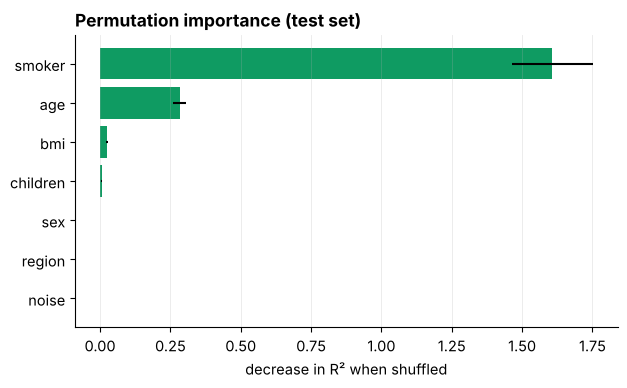

In [4]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=0, scoring="r2", n_jobs=-1)
pim = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X_te.columns).sort_values("mean")
print(pim.round(4).iloc[::-1])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(pim.index, pim["mean"], xerr=pim["sd"], color="#0f9b62")
ax.set(xlabel="decrease in R² when shuffled", title="Permutation importance (test set)")
ax.grid(axis="y", visible=False)
plt.show()

## 25.4 Partial dependence and ICE plots · *Intermediate*

**How do age and BMI affect predicted charges?**

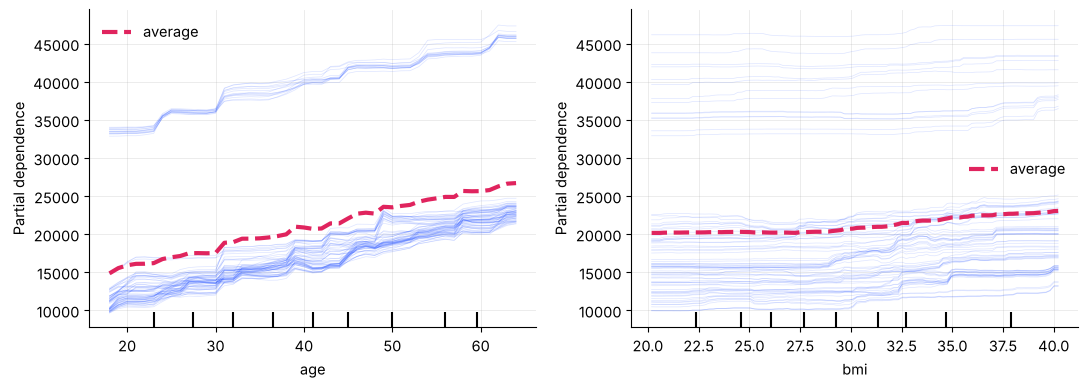

In [5]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PartialDependenceDisplay.from_estimator(rf, X_te, features=["age", "bmi"], kind="both",
                                        subsample=80, random_state=0, ax=axes,
                                        ice_lines_kw={"alpha": 0.15}, pd_line_kw={"color": "#e0245e", "lw": 3})
plt.tight_layout()
plt.show()

**Two-way partial dependence**

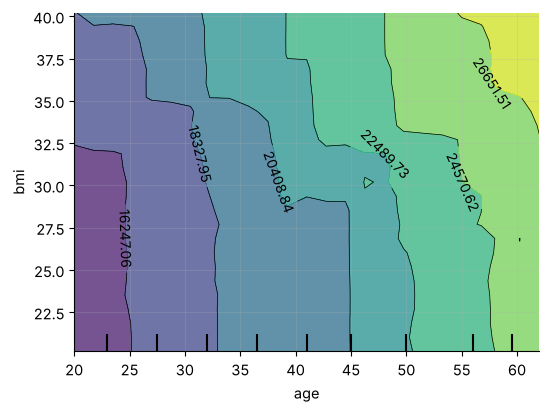

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.4))
PartialDependenceDisplay.from_estimator(rf, X_te, features=[("age", "bmi")], grid_resolution=25, ax=ax)
plt.show()

## 25.5 SHAP values · *Advanced*

**SHAP for a tree model (requires the shap package)**

*Shown for reference, not run automatically (it waits for input, needs your own files, or would change your system). Copy it into a cell to try it.*

```python
import shap

pre_fitted, model = rf.named_steps["pre"], rf.named_steps["m"]
X_te_t = pd.DataFrame(pre_fitted.transform(X_te), columns=pre_fitted.get_feature_names_out())
explainer = shap.TreeExplainer(model)
sv = explainer(X_te_t)
shap.plots.beeswarm(sv)
shap.plots.waterfall(sv[0])
```

## 25.6 Saving and loading models · *Beginner*

**joblib: the standard way**

In [7]:
import joblib, sklearn, json, platform

joblib.dump(rf, "insurance_rf.joblib")
loaded = joblib.load("insurance_rf.joblib")
print(np.allclose(loaded.predict(X_te), rf.predict(X_te)))
meta = {"sklearn": sklearn.__version__, "python": platform.python_version(),
        "features": list(X.columns), "test_r2": round(rf.score(X_te, y_te), 4)}
with open("insurance_rf.meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print(meta)

True
{'sklearn': '1.9.1', 'python': '3.13.18', 'features': ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'noise'], 'test_r2': 0.928}


## Try it yourself

1. Compute permutation importance with `scoring="neg_mean_absolute_error"`. Does the ranking change?
2. Draw ICE plots for `children`. Is the effect the same for everyone?
3. Save a fitted pipeline, restart Python, load it, and predict for a brand-new customer DataFrame.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 25*.